# The Rosenbrock function with piazzi

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cai4cai/torch-piazzi/blob/main/notebooks/rosenbrock.ipynb)

The Rosenbrock function is the classic test problem for unconstrained minimisation:

$$f(x, y) = (1 - x)^2 + 100\,(y - x^2)^2 .$$

Its global minimum $f = 0$ sits at $(1, 1)$, at the bottom of a long, curved, nearly flat valley. Finding the valley is easy; following it to the minimum is what makes the problem hard for first-order methods.

This notebook takes its cue from two examples:

- the [Ceres Solver gradient tutorial](https://ceres-solver.readthedocs.io/latest/gradient_tutorial.html), which minimises $f$ from $(-1.2, 1)$ with L-BFGS, and
- the [pytorch-minimize Rosenbrock example](https://github.com/rfeinman/pytorch-minimize/blob/main/examples/rosen_minimize.ipynb), which compares several `scipy.optimize.minimize`-style methods in PyTorch.

We look at the problem in two ways:

1. as a **scalar function**, minimised with `piazzi.minimize` (L-BFGS with an Armijo line search), using only values and gradients;
2. as a **least-squares problem**, $f = r_1^2 + r_2^2$ with residuals $r_1 = 1 - x$ and $r_2 = 10\,(y - x^2)$, solved with Gauss-Newton and Levenberg-Marquardt through `piazzi.least_squares`.

We then compare with SciPy's methods through `piazzi.scipy`, and finish with the $N$-dimensional version.

## Setup

On Colab, the next cell installs `piazzi` from GitHub. Locally, install the notebook dependencies with `uv sync --group notebooks` (see the README).

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q git+https://github.com/cai4cai/torch-piazzi

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize
import torch
from matplotlib.colors import LogNorm

import piazzi
import piazzi.scipy

torch.set_default_dtype(torch.float64)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["legend.fontsize"] = 12
plt.rcParams["axes.labelsize"] = 14

## The problem

`rosen` is the scalar function and `residuals` its least-squares form. They agree: $f = \|r\|^2$. Note that `piazzi.least_squares`, like SciPy, minimises $\tfrac12\|r\|^2 = f / 2$, so its `result.fun` is half of $f$; the minimiser is the same.

We start from $(-1.2, 1)$, as in the Ceres tutorial and most of the literature.

In [3]:
def rosen(x):
    return (1 - x[0]) ** 2 + 100 * (x[1] - x[0] ** 2) ** 2


def residuals(x):
    return torch.stack([1 - x[0], 10 * (x[1] - x[0] ** 2)])


x0 = torch.tensor([-1.2, 1.0])
x_star = torch.tensor([1.0, 1.0])
print(f"f(x0) = {rosen(x0).item():.4g},  ||r(x0)||^2 = {residuals(x0).square().sum().item():.4g}")

f(x0) = 24.2,  ||r(x0)||^2 = 24.2


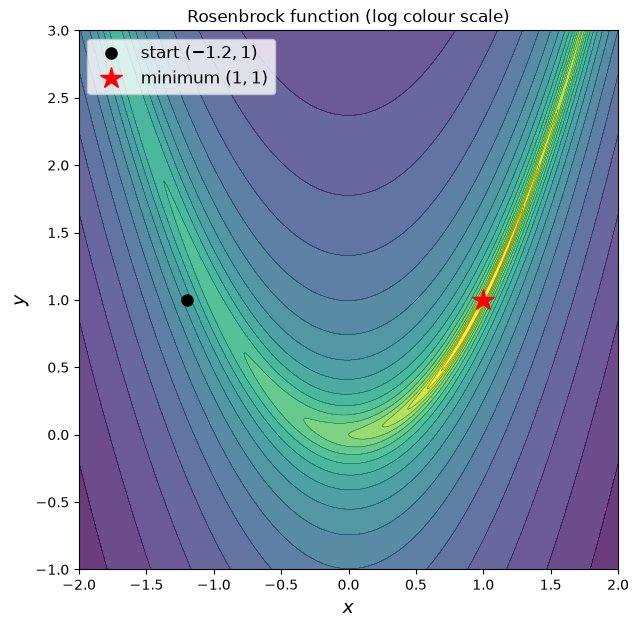

In [4]:
xs = torch.linspace(-2, 2, 401)
ys = torch.linspace(-1, 3, 401)
X, Y = torch.meshgrid(xs, ys, indexing="xy")
Z = rosen(torch.stack([X, Y]))


def plot_landscape(ax):
    levels = np.logspace(-1, 3.5, 19)
    ax.contourf(X, Y, Z + 1e-3, levels=levels, norm=LogNorm(), cmap="viridis_r", alpha=0.8, extend="min")
    ax.contour(X, Y, Z + 1e-3, levels=levels, norm=LogNorm(), colors="k", linewidths=0.3, alpha=0.5)
    ax.plot(*x0, "ko", ms=8, label="start $(-1.2, 1)$")
    ax.plot(*x_star, "r*", ms=16, label="minimum $(1, 1)$")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(7, 7))
plot_landscape(ax)
ax.set_title("Rosenbrock function (log colour scale)")
ax.legend(loc="upper left");

## Recording the iterates

Every piazzi solver accepts a `callback(info)`, called after each iteration with an `IterationInfo`. A rejected Levenberg-Marquardt step also triggers it (with `info.accepted == False` and `x` unchanged), so we keep only accepted points.

`piazzi.scipy` passes `callback` straight to SciPy. SciPy hands its intermediate `OptimizeResult` (with NumPy arrays) only to a callback whose single parameter is named `intermediate_result`; otherwise the callback receives the bare array `xk`.

In [5]:
class Trace:
    """Records the accepted iterates of a piazzi or SciPy run, starting at x0."""

    def __init__(self):
        self.xs = [x0.clone()]

    def __call__(self, info):  # piazzi callback
        if info.accepted:
            self.xs.append(info.x.clone())

    def scipy(self, intermediate_result):  # SciPy callback: the parameter name matters
        self.xs.append(torch.as_tensor(intermediate_result.x).clone())

    @property
    def path(self):
        return torch.stack(self.xs)

    @property
    def values(self):
        return torch.stack([rosen(x) for x in self.xs])

## 1. Scalar minimisation with L-BFGS

`piazzi.minimize` mirrors `scipy.optimize.minimize`; its default method is `lbfgs_armijo`. Each iteration first tries the full L-BFGS step, evaluating value and gradient together (one autograd pass). If that point does not decrease $f$ enough, the line search backtracks with value-only evaluations.

Ceres reports 36 iterations and 44 value-and-gradient evaluations from the same start, with L-BFGS (memory 20) and a cubic-interpolation Wolfe line search. The Armijo line search here does not enforce the curvature condition, so it needs a few more iterations, but it keeps most iterations at a single evaluation.

In [6]:
trace_lbfgs = Trace()
res_lbfgs = piazzi.minimize(rosen, x0, callback=trace_lbfgs, options={"max_iter": 200})
print(res_lbfgs.message)
print(f"x = {res_lbfgs.x.tolist()},  f = {res_lbfgs.fun.item():.2e}")
r = res_lbfgs
print(f"{r.n_iter} iterations, {r.n_fun_grad} value+gradient and {r.n_fun} value-only evaluations")

step below step_tol
x = [0.9999999986168775, 0.9999999972153758],  f = 1.95e-18
42 iterations, 51 value+gradient and 10 value-only evaluations


## 2. Least squares: Gauss-Newton and Levenberg-Marquardt

Written as residuals, the problem has more structure to exploit. With the Jacobian

$$J = \begin{pmatrix} -1 & 0 \\ -20x & 10 \end{pmatrix},$$

the gradient of $\tfrac12\|r\|^2$ is $J^\top r$, and $J^\top J$ is a positive semi-definite model of its Hessian. `piazzi.least_squares` builds both with forward-mode autodiff and solves the normal equations:

- `method="gn"`: Gauss-Newton steps with an Armijo backtracking line search;
- `method="lm"` (the default): Levenberg-Marquardt, which blends Gauss-Newton with gradient descent through a damping parameter.

The first Gauss-Newton step from $(-1.2, 1)$ linearises the parabola $y = x^2$, so it jumps straight to $x = 1$ but lands far below the valley, at $y = -3.84$, where $f \approx 2343$. The line search shrinks it, and steps are also capped at `max_step=1` per coordinate by default. We set a tighter `step_tol` than the default `1e-5` to converge to machine precision.

In [7]:
trace_gn, trace_lm = Trace(), Trace()
res_gn = piazzi.least_squares(residuals, x0, method="gn", callback=trace_gn, step_tol=1e-10)
res_lm = piazzi.least_squares(residuals, x0, method="lm", callback=trace_lm, step_tol=1e-10)
for name, res in [("Gauss-Newton", res_gn), ("Levenberg-Marquardt", res_lm)]:
    print(f"{name}: {res.message}")
    print(f"  x = {res.x.tolist()},  f = {rosen(res.x).item():.2e}")
    print(f"  {res.n_iter} iterations, {res.n_system} residual+Jacobian and {res.n_fun} residual-only evaluations")

Gauss-Newton: step below step_tol
  x = [0.9999999999999999, 0.9999999999999997],  f = 1.24e-30
  14 iterations, 23 residual+Jacobian and 14 residual-only evaluations
Levenberg-Marquardt: step below step_tol
  x = [0.999999999999996, 0.9999999999999921],  f = 1.72e-29
  18 iterations, 19 residual+Jacobian and 2 residual-only evaluations


### Paths and convergence

All three methods spend their first iterations working round the bend of the valley. L-BFGS has to learn the curvature from successive gradients, so it creeps along the flat valley floor for about 30 iterations before it speeds up near the minimum. Gauss-Newton and Levenberg-Marquardt get a curvature model from the Jacobian at every iterate, and converge quadratically once they are close: the residuals vanish at the solution, which is exactly when $J^\top J$ matches the true Hessian.

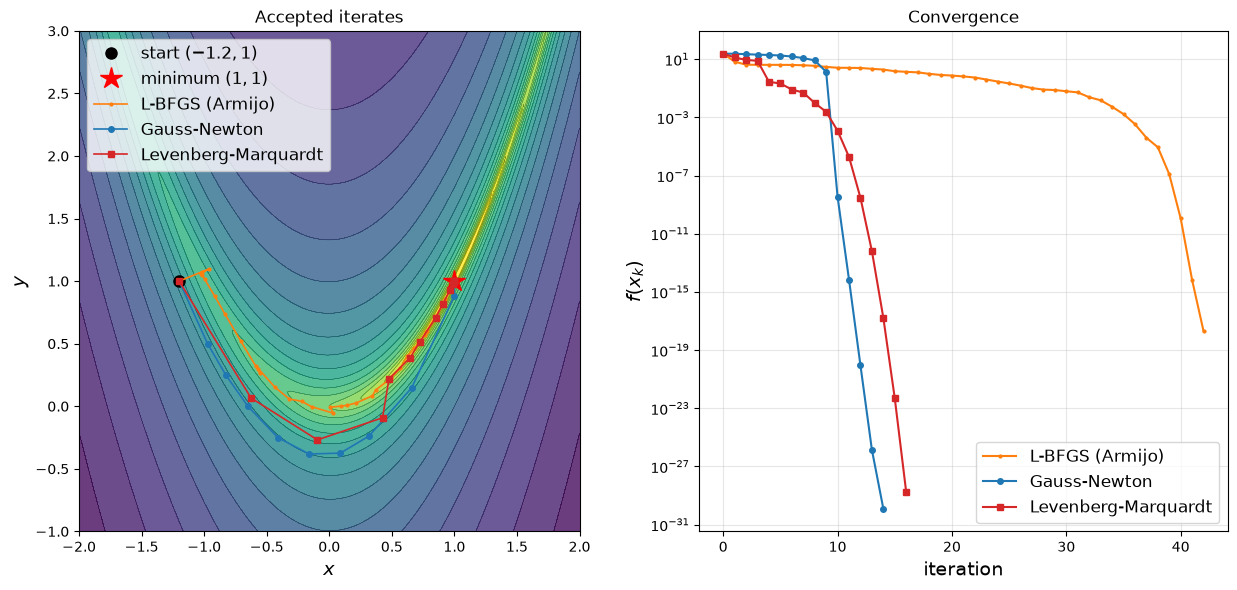

In [8]:
traces = {"L-BFGS (Armijo)": trace_lbfgs, "Gauss-Newton": trace_gn, "Levenberg-Marquardt": trace_lm}
styles = {"L-BFGS (Armijo)": "C1.-", "Gauss-Newton": "C0o-", "Levenberg-Marquardt": "C3s-"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5))
plot_landscape(ax1)
for name, trace in traces.items():
    ax1.plot(*trace.path.T, styles[name], ms=4, lw=1.2, label=name)
ax1.set_xlim(-2, 2)
ax1.set_ylim(-1, 3)
ax1.legend(loc="upper left")
ax1.set_title("Accepted iterates")

for name, trace in traces.items():
    ax2.semilogy(trace.values.clamp(min=1e-32), styles[name], ms=4, label=name)
ax2.set_xlabel("iteration")
ax2.set_ylabel("$f(x_k)$")
ax2.set_title("Convergence")
ax2.grid(True, which="major", alpha=0.3)
ax2.legend();

## 3. Comparison with SciPy

`piazzi.scipy.minimize` and `piazzi.scipy.least_squares` run SciPy's solvers on the same PyTorch functions, with gradients, Jacobians, Hessians or Hessian-vector products from autograd. This mirrors the method comparison in the pytorch-minimize example.

The evaluation counts are what each solver reports:

- `value+grad`: evaluations of $f$ and its gradient together (one autograd pass);
- `value`: value-only evaluations (L-BFGS line search, or the derivative-free Nelder-Mead);
- `residual+J`: Jacobian evaluations of the least-squares solvers. piazzi counts its residual-only evaluations under `value`, while SciPy's `nfev` counts every residual evaluation, including those where it also asks for the Jacobian.

Newton-type methods also evaluate Hessians or Hessian-vector products, which the table does not count.

In [9]:
runs = {
    "piazzi L-BFGS (Armijo)": res_lbfgs,
    "piazzi Gauss-Newton": res_gn,
    "piazzi Levenberg-Marquardt": res_lm,
}
scipy_runs = {
    "BFGS": {},
    "L-BFGS-B": {},
    "CG": {},
    "Newton-CG": {"hessp": "autodiff"},
    "trust-krylov": {"hessp": "autodiff"},
    "trust-exact": {"hess": "autodiff"},
    "Nelder-Mead": {"jac": None},
}
for method, kwargs in scipy_runs.items():
    runs[f"scipy {method}"] = piazzi.scipy.minimize(rosen, x0, method=method, **kwargs)
for method in ["trf", "lm"]:
    runs[f"scipy least_squares {method}"] = piazzi.scipy.least_squares(residuals, x0, method=method)

print(f"{'solver':32s} {'iter':>5s} {'value+grad':>11s} {'value':>6s} {'residual+J':>11s}", end="")
print(f" {'f(x)':>9s} {'max|x-1|':>9s}")
for name, res in runs.items():
    print(
        f"{name:32s} {res.n_iter:5d} {res.n_fun_grad:11d} {res.n_fun:6d} {res.n_system:11d}"
        f" {rosen(res.x).item():9.1e} {(res.x - 1).abs().max().item():9.1e}"
    )

solver                            iter  value+grad  value  residual+J      f(x)  max|x-1|
piazzi L-BFGS (Armijo)              42          51     10           0   1.9e-18   2.8e-09
piazzi Gauss-Newton                 14           0     14          23   1.2e-30   3.3e-16
piazzi Levenberg-Marquardt          18           0      2          19   1.7e-29   7.9e-15
scipy BFGS                          32          39      0           0   2.5e-15   5.4e-08
scipy L-BFGS-B                      36          44      0           0   2.8e-12   2.0e-06
scipy CG                            36          78      0           0   1.9e-14   5.5e-09
scipy Newton-CG                     83         105      0           0   3.0e-10   3.5e-05
scipy trust-krylov                  36          37      0           0   4.9e-09   1.4e-04
scipy trust-exact                   25          26      0           0   3.3e-19   1.1e-09
scipy Nelder-Mead                   85           0    159           0   8.2e-10   4.2e-05
scipy leas

All solvers reach $(1, 1)$, each to the accuracy its own stopping rule allows. The quasi-Newton methods (piazzi's L-BFGS, SciPy's BFGS and L-BFGS-B) need 30 to 40 iterations. Second-order information helps only when it is used well: trust-exact, with the exact Hessian, takes 25 iterations, while Newton-CG and trust-krylov, which use Hessian-vector products, are no faster than BFGS here. Nelder-Mead, which uses no derivatives at all, needs the most evaluations.

Gauss-Newton and Levenberg-Marquardt need only first derivatives of the *residuals*, yet converge like Newton's method here. That is the point of the least-squares formulation: when the residuals are small at the solution, $J^\top J$ is a good Hessian for free.

## 4. The $N$-dimensional Rosenbrock function

The usual generalisation, used by `scipy.optimize.rosen`, chains the 2-D function over neighbouring coordinates:

$$f(x) = \sum_{i=1}^{N-1} \left[ 100\,(x_{i+1} - x_i^2)^2 + (1 - x_i)^2 \right],$$

with $2(N - 1)$ residuals $10\,(x_{i+1} - x_i^2)$ and $1 - x_i$. The global minimum is still at $x = (1, \dots, 1)$, but for $N \ge 4$ there is also a local minimum near $(-1, 1, \dots, 1)$. We start from $(-1.2, 1, -1.2, 1, \dots)$ with $N = 10$, and check our definition against SciPy's.

In [10]:
def rosen_nd(x):
    return (100 * (x[1:] - x[:-1] ** 2) ** 2 + (1 - x[:-1]) ** 2).sum()


def residuals_nd(x):
    return torch.cat([10 * (x[1:] - x[:-1] ** 2), 1 - x[:-1]])


N = 10
x0_nd = torch.tensor([-1.2, 1.0]).repeat(N // 2)
assert np.isclose(rosen_nd(x0_nd).item(), scipy.optimize.rosen(x0_nd.numpy()))
assert torch.isclose(residuals_nd(x0_nd).square().sum(), rosen_nd(x0_nd))

runs_nd = {
    "piazzi L-BFGS (Armijo)": piazzi.minimize(rosen_nd, x0_nd, options={"max_iter": 500}),
    "piazzi Gauss-Newton": piazzi.least_squares(residuals_nd, x0_nd, method="gn", step_tol=1e-10, max_iter=500),
    "piazzi Levenberg-Marquardt": piazzi.least_squares(residuals_nd, x0_nd, step_tol=1e-10, max_iter=500),
    "scipy BFGS": piazzi.scipy.minimize(rosen_nd, x0_nd, method="BFGS"),
    "scipy L-BFGS-B": piazzi.scipy.minimize(rosen_nd, x0_nd, method="L-BFGS-B"),
    "scipy trust-exact": piazzi.scipy.minimize(rosen_nd, x0_nd, method="trust-exact", hess="autodiff"),
    "scipy least_squares trf": piazzi.scipy.least_squares(residuals_nd, x0_nd),
}
print(f"{'solver':28s} {'iter':>5s} {'value+grad':>11s} {'value':>6s} {'residual+J':>11s} {'f(x)':>9s}  x[:3]")
for name, res in runs_nd.items():
    print(
        f"{name:28s} {res.n_iter:5d} {res.n_fun_grad:11d} {res.n_fun:6d} {res.n_system:11d}"
        f" {rosen_nd(res.x).item():9.1e}  {np.round(res.x[:3].numpy(), 4)}"
    )

solver                        iter  value+grad  value  residual+J      f(x)  x[:3]
piazzi L-BFGS (Armijo)          82          97     14           0   1.1e-11  [1. 1. 1.]
piazzi Gauss-Newton             21           0     10          32   5.3e-30  [1. 1. 1.]
piazzi Levenberg-Marquardt      27           0      2          27   2.5e-30  [1. 1. 1.]
scipy BFGS                      73          83      0           0   4.0e+00  [-0.9933  0.9966  0.9982]
scipy L-BFGS-B                  71          88      0           0   1.0e-11  [1. 1. 1.]
scipy trust-exact               29          30      0           0   4.0e+00  [-0.9933  0.9966  0.9982]
scipy least_squares trf         22           0     24          22   1.5e-28  [1. 1. 1.]


SciPy's BFGS and trust-exact both settle in the local minimum near $(-1, 1, \dots, 1)$, with $f \approx 3.99$, and report success: it is a genuine stationary point. Which basin a solver ends up in depends on its first few steps, not on how well it converges. The other solvers find the global minimum.

The gap between the least-squares solvers and L-BFGS widens with $N$. The Jacobian costs one forward-mode pass per parameter, which is cheap for the small problems piazzi targets.

## 5. Single precision

piazzi always solves the small normal equations in float64 on the CPU (`solve_dtype`, `solve_device`), so the objective itself can run in float32, for example on a GPU. Both formulations still reach the minimum in float32.

In [11]:
x0_32 = x0.float()
res32_lbfgs = piazzi.minimize(rosen, x0_32)
res32_lm = piazzi.least_squares(residuals, x0_32)
for name, res in [("L-BFGS (Armijo)", res32_lbfgs), ("Levenberg-Marquardt", res32_lm)]:
    print(f"{name:20s} {res.x.dtype}  x = {res.x.tolist()}  ({res.n_iter} iterations, {res.message})")

L-BFGS (Armijo)      torch.float32  x = [1.0, 1.0]  (42 iterations, step below step_tol)
Levenberg-Marquardt  torch.float32  x = [1.0, 1.0]  (16 iterations, step below step_tol)


## Summary

- As a scalar function, the Rosenbrock function is a hard test for quasi-Newton methods: `piazzi.minimize` (L-BFGS with an Armijo line search) needs about 40 iterations, a few more than Ceres (36) and SciPy's BFGS (32).
- Written as residuals, the same problem is easy for Gauss-Newton and Levenberg-Marquardt (`piazzi.least_squares`), which use the Jacobian to model the curvature and converge to machine precision in under 20 iterations.
- `piazzi.scipy` runs SciPy's solvers on the same PyTorch functions, with derivatives from autograd, so you can compare backends without rewriting the problem.